# Quickstart: Clinical Data Exploratory Data Analysis (EDA)

**RSU, Bioinformatics group** · companion notebook to the slide deck in `slides/`

This notebook walks through a complete EDA of one clinical dataset, in the same order as the slides:

| Step | Section | What it produces |
|---|---|---|
| 0 | Study question and data dictionary | the question, the unit of analysis, variable meanings |
| 1 | Load and first look | a table read with the right missing codes and types |
| 2 | Clean and clinical checks | consistent labels, plausible values, a decision log |
| 3 | Explore distributions, groups and relationships | plots and shape summaries |
| 4 | Outliers | flags, judged against clinical plausibility |
| 5 | Missing data | patterns, plausible reasons, a simulation, multiple imputation |
| 6 | Features | BMI, encodings, scaling versus transformation |
| 7A | Statistical inference | effect estimates with confidence intervals, multiplicity, confounding |
| 7B | Predictive modelling | a leakage-safe pipeline with patient-grouped validation |
| 8 | Report | Table 1, saved figures, the decision log |

**Dataset.** `data/clinic_visits.csv` is **synthetic**: no real patients. It imitates a cardiovascular risk clinic
(3 sites, 2022 to 2025) and contains problems planted on purpose. `scripts/make_dataset.py` regenerates it exactly.

**Reusable code** lives in `scripts/`, so the notebook shows the reasoning and the functions can be reused on other datasets.

## Setup

Create the environment once from a terminal (full instructions in `README.md`):

```bash
python3 -m venv .venv
source .venv/bin/activate            # Windows: .venv\Scripts\activate
python3 -m pip install -r requirements.txt
python3 -m jupyter lab               # then open eda_tutorial.ipynb
```

Inside a notebook, `%pip install <package>` installs into the kernel that is running, which avoids
installing into a different Python by mistake.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from scripts.cleaning import (DecisionLog, load_visits, parse_censored, plausibility_flags,
                              standardise_labels, visit_order_problems)
from scripts.summaries import build_table1, fmt_continuous, shape_table
from scripts.comparisons import (adjusted_effect, compare_groups, geometric_mean_ratio,
                                 mean_difference)
from scripts.missingness import (compare_by_missingness, missing_by, missing_summary,
                                 simulate_missing)
from scripts import plots

plots.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

DATA = Path("data")
FIG = Path("outputs/figures")
FIG.mkdir(parents=True, exist_ok=True)
log = DecisionLog()     # every cleaning and analysis decision is recorded here

---
## 0 · Study question and data dictionary

A written question decides which rows, variables and comparisons matter, and keeps exploration from
turning into a search for significant results.

| | |
|---|---|
| **Population** | Adults attending a cardiovascular risk clinic at sites A, B and C |
| **Comparison** | Patients with diabetes versus without diabetes |
| **Outcome** | Systolic blood pressure (mmHg) at the baseline visit |
| **Unit of analysis** | One row = one clinic visit. The study question uses one row per patient (visit 1). |

In [2]:
dictionary = pd.read_csv(DATA / "data_dictionary.csv")
dictionary

,variable,type,unit,coding_and_notes
0,patient_id,identifier,NaN,P0001 to P0420; never used as a model input
1,visit,discrete,NaN,1 = baseline; 2 = follow-up
2,visit_date,date,NaN,YYYY-MM-DD
3,site,nominal,NaN,"A, B, C"
4,age,continuous,years,age at the visit
5,sex,binary (nominal),NaN,"female, male"
6,height_cm,continuous,cm,measured at the visit
7,weight_kg,continuous,kg,measured at the visit
8,systolic_bp,continuous,mmHg,"seated, clinic measurement"
9,diastolic_bp,continuous,mmHg,"seated, clinic measurement"


---
## 1 · Load and first look

Missing-value codes (`-99`, blanks) are declared **at load time**, so a code never enters a mean.
Dates are parsed on import so that visit order and follow-up intervals can be checked.

In [3]:
raw = load_visits(DATA / "clinic_visits.csv")   # pd.read_csv(..., na_values=["", "NA", -99], parse_dates=["visit_date"])
df = raw.copy()
df.head(8)

,patient_id,visit,visit_date,site,age,sex,height_cm,weight_kg,systolic_bp,diastolic_bp,cholesterol_total,hdl,crp,smoking_status,diabetes,statin,ccs_class
0,P0001,1,2023-10-26,A,59,female,165.9,89.0,132,63,256.0,56.0,15.81,former,0,0,1
1,P0002,1,2022-08-13,B,64,female,171.0,96.9,135,82,NaN,NaN,<0.3,former,1,0,0
2,P0003,1,2023-11-14,B,75,male,179.6,74.7,115,66,220.0,42.0,4.68,current,0,0,1
3,P0003,2,2024-08-06,B,75,male,179.6,76.0,132,62,198.0,38.0,6.75,current,0,0,1
4,P0004,1,2022-06-26,A,62,female,166.4,70.3,132,56,281.0,45.0,0.34,current,0,0,1
5,P0004,2,2023-04-10,A,62,female,166.4,66.7,134,58,262.0,42.0,0.47,current,0,0,1
6,P0005,1,2022-12-20,A,63,female,149.6,59.2,116,62,198.0,59.0,4.78,former,0,1,0
7,P0006,1,2024-03-05,B,75,male,184.6,87.0,142,77,181.0,39.0,3.88,former,0,0,0


### Structure before statistics
Four questions come before any summary: (i) how many rows and how many patients, (ii) are the column
types right, (iii) are category labels consistent, (iv) do the ranges make sense?

In [4]:
print(f"{len(df)} rows (visits), {df['patient_id'].nunique()} patients")
print(df["visit"].value_counts().rename("visits by number").to_string(), "\n")
df.info()

550 rows (visits), 420 patients
visit
1    424
2    126 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   patient_id         550 non-null    object        
 1   visit              550 non-null    int64         
 2   visit_date         550 non-null    datetime64[ns]
 3   site               550 non-null    object        
 4   age                550 non-null    int64         
 5   sex                550 non-null    object        
 6   height_cm          538 non-null    float64       
 7   weight_kg          510 non-null    float64       
 8   systolic_bp        550 non-null    int64         
 9   diastolic_bp       550 non-null    int64         
 10  cholesterol_total  505 non-null    float64       
 11  hdl                501 non-null    float64       
 12  crp                384 non-null    object        
 13  smoking

In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
patient_id,550,420,P0194,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visit,550.0,NaN,NaN,NaN,1.229091,1.0,1.0,1.0,1.0,2.0,0.42063
visit_date,550,NaN,NaN,NaN,2023-03-29 02:16:08.727272704,2022-01-10 00:00:00,2022-08-26 00:00:00,2023-03-22 12:00:00,2023-10-22 00:00:00,2025-02-16 00:00:00,NaN
site,550,3,A,249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,550.0,NaN,NaN,NaN,58.267273,35.0,51.25,58.0,65.0,85.0,9.813907
sex,550,5,male,285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
height_cm,538.0,NaN,NaN,NaN,170.788848,17.2,163.9,171.0,178.3,201.3,11.319791
weight_kg,510.0,NaN,NaN,NaN,80.342941,41.4,69.8,79.3,91.275,130.6,15.484034
systolic_bp,550.0,NaN,NaN,NaN,121.709091,71.0,110.0,122.0,133.0,212.0,16.618151
diastolic_bp,550.0,NaN,NaN,NaN,64.329091,38.0,58.0,64.0,71.0,128.0,10.145161


In [6]:
for col in ["sex", "site", "smoking_status"]:
    print(df[col].value_counts(dropna=False).to_string(), "\n")

sex
male      285
female    256
F           4
Male        3
Female      2 

site
A    249
B    209
C     92 

smoking_status
never      287
former     167
current     83
NaN         13 



**What the first look shows**
* `crp` has an object (text) type: values such as `"<0.3"` block numeric conversion.
* `sex` has five spellings: `female`, `male`, `F`, `Female`, `"Male "` (trailing space).
* The minimum `height_cm` is 17.2 and some `cholesterol_total` values are around 5: entry and unit problems.
* Repeated `patient_id` values are follow-up visits, which are legitimate; exact duplicates are checked in step 2.

### Optional: an automated profile report
`fg-data-profiling` (formerly `ydata-profiling`; the old package no longer receives updates) builds an HTML
overview of types, distributions, missingness and correlations. It flags problems but does not decide what to do
about them. On this dataset it reports the 4 duplicate rows and the missingness, but not the unit mismatch,
the impossible blood pressures or the misdated visit. Set `RUN_PROFILE = True` to build it (about 30 seconds).

In [7]:
RUN_PROFILE = False
if RUN_PROFILE:
    from data_profiling import ProfileReport          # older tutorials: from ydata_profiling import ...
    profile = ProfileReport(raw, title="Clinic visits: EDA report")
    profile.to_file("outputs/eda_report.html")         # open in a browser
    # profile.to_notebook_iframe()                     # or show it inside the notebook

---
## 2 · Clean and run clinical checks

Cleaning makes the table **consistent**; clinical checks make it **plausible**. Every change below is
written to the decision log with the number of rows affected.

### 2.1 Labels, types and below-detection-limit values
CRP results below the assay limit are **censored**, not missing and not zero. They are set to half the limit
(0.15 mg/L), a common documented convention, and a flag column keeps the information for a sensitivity analysis.

In [8]:
n_bad_sex = (~df["sex"].isin(["female", "male"]) & df["sex"].notna()).sum()
df["sex"] = standardise_labels(df["sex"], {"f": "female", "m": "male"})
log.add("2 Clean", "sex had 5 spellings", n_bad_sex, "standardised to female / male")

df["crp"], df["crp_below_lod"] = parse_censored(df["crp"], substitute="half")
log.add("2 Clean", 'CRP recorded as "<0.3" (below detection limit)', df["crp_below_lod"].sum(),
        "set to 0.15 mg/L (LOD/2); flag kept in crp_below_lod")

print(df["sex"].value_counts(dropna=False).to_string())
print("CRP below LOD:", df["crp_below_lod"].sum(), "| crp dtype:", df["crp"].dtype)

sex
male      288
female    262
CRP below LOD: 9 | crp dtype: float64


### 2.2 Duplicates versus repeat visits
An **exact duplicate** is the same record entered twice. A **repeat visit** is a new measurement of the same
patient and is kept. A second check ignores the identifier: identical measurements under two different IDs
would suggest one patient registered twice.

In [9]:
n_exact = df.duplicated().sum()
print("Exact duplicate rows:", n_exact)
df = df.drop_duplicates().copy()
log.add("2 Clean", "exact duplicate records", n_exact, "removed (copies of another row)")

print("Same patient and visit number twice:", df.duplicated(["patient_id", "visit"]).sum())
measure_cols = [c for c in df.columns if c not in ["patient_id"]]
print("Identical measurements under different patient_id:", df.duplicated(measure_cols).sum())
print("Legitimate follow-up visits kept:", (df["visit"] == 2).sum())

Exact duplicate rows: 4
Same patient and visit number twice: 0
Identical measurements under different patient_id: 0
Legitimate follow-up visits kept: 126


### 2.3 Unit mismatches
A summary **by site and period** exposes a unit change that an overall summary hides.

In [10]:
(df.assign(year=df["visit_date"].dt.year)
   .groupby(["site", "year"])["cholesterol_total"]
   .agg(["count", "median", "min", "max"])
   .round(1))

count  median    min    max
site year                             
A    2022    101   205.0   75.0  294.0
     2023    108   204.5  103.0  302.0
     2024     38   186.0   96.0  300.0
B    2022     43   196.0  112.0  262.0
     2023     83   183.0   85.0  298.0
     2024     35   198.0   57.0  294.0
     2025      2   236.0  213.0  259.0
C    2022     31   188.0   86.0  245.0
     2023     46     5.0    3.2    8.0
     2024     14   182.0  144.0  243.0
     2025      1   214.0  214.0  214.0

In [11]:
mmol = df["cholesterol_total"] < 20
print(df.loc[mmol, "site"].value_counts().to_string(), "\n", df.loc[mmol, "visit_date"].dt.year.value_counts().to_string())
df.loc[mmol, "cholesterol_total"] = (df.loc[mmol, "cholesterol_total"] * 38.67).round(0)
log.add("2 Clean", "cholesterol in mmol/L at site C, 2023", mmol.sum(),
        "converted to mg/dL (x 38.67) after confirming with the site")

site
C    46 
 visit_date
2023    46


### 2.4 Clinical plausibility: impossible values and combinations
Domain knowledge sets the limits. Ranges are deliberately wide: they catch impossible or mistyped values,
not unusual but real patients. Systolic pressure must exceed diastolic pressure; a height of 17.2 cm is
almost certainly 172 cm typed wrongly. Values that cannot be resolved from source records are set to missing,
not deleted with the whole row.

In [12]:
flags = plausibility_flags(df)
print(flags.sum().to_string(), "\n")
problem_rows = flags.any(axis=1)
df.loc[problem_rows, ["patient_id", "visit", "height_cm", "systolic_bp", "diastolic_bp", "cholesterol_total"]]

systolic_bp outside 60-260 mmHg     0
diastolic_bp outside 30-150 mmHg    0
diastolic_bp >= systolic_bp         2
height_cm outside 120-220           1
weight_kg outside 30-250            0
cholesterol_total < 20 (mmol/L?)    0 



,patient_id,visit,height_cm,systolic_bp,diastolic_bp,cholesterol_total
12,P0011,1,17.2,135,75,180.0
57,P0047,1,170.2,78,121,176.0
234,P0178,2,163.9,82,128,187.0


In [13]:
bp_bad = flags["diastolic_bp >= systolic_bp"]
df.loc[bp_bad, ["systolic_bp", "diastolic_bp"]] = np.nan
log.add("2 Clean", "diastolic >= systolic (likely swapped at entry)", bp_bad.sum(),
        "both values set to missing; source query raised")

h_bad = flags["height_cm outside 120-220"]
df.loc[h_bad, "height_cm"] = np.nan
log.add("2 Clean", "height_cm = 17.2 (likely 172)", h_bad.sum(), "set to missing; source query raised")

### 2.5 Inconsistent dates

In [14]:
bad_date = visit_order_problems(df)
display(df[df["patient_id"].isin(df.loc[bad_date, "patient_id"])][["patient_id", "visit", "visit_date"]])
df.loc[bad_date, "visit_date"] = pd.NaT
log.add("2 Clean", "follow-up dated before baseline", bad_date.sum(), "date set to missing; visit kept")

,patient_id,visit,visit_date
27,P0023,1,2022-07-12
28,P0023,2,2022-06-02


### 2.6 The analysis dataset for the study question
One row per patient: the baseline visit.

In [15]:
base = df[df["visit"] == 1].copy()
log.add("2 Clean", "unit of analysis", len(base), "baseline visit (visit 1), one row per patient")
print(len(base), "patients,", base["diabetes"].sum(), "with diabetes")
log.to_frame()

420 patients, 83 with diabetes


,step,issue,rows_affected,decision
0,2 Clean,sex had 5 spellings,9,standardised to female / male
1,2 Clean,"CRP recorded as ""<0.3"" (below detection limit)",9,set to 0.15 mg/L (LOD/2); flag kept in crp_bel...
2,2 Clean,exact duplicate records,4,removed (copies of another row)
3,2 Clean,"cholesterol in mmol/L at site C, 2023",46,converted to mg/dL (x 38.67) after confirming ...
4,2 Clean,diastolic >= systolic (likely swapped at entry),2,both values set to missing; source query raised
5,2 Clean,height_cm = 17.2 (likely 172),1,set to missing; source query raised
6,2 Clean,follow-up dated before baseline,1,date set to missing; visit kept
7,2 Clean,unit of analysis,420,"baseline visit (visit 1), one row per patient"


---
## 3 · Explore distributions, groups and relationships

### 3.1 Categorical variables
Counts are reported as **n/N (%)**, with N the non-missing values. Bar charts are preferred to pie charts:
lengths on a common baseline are easier to compare than angles.

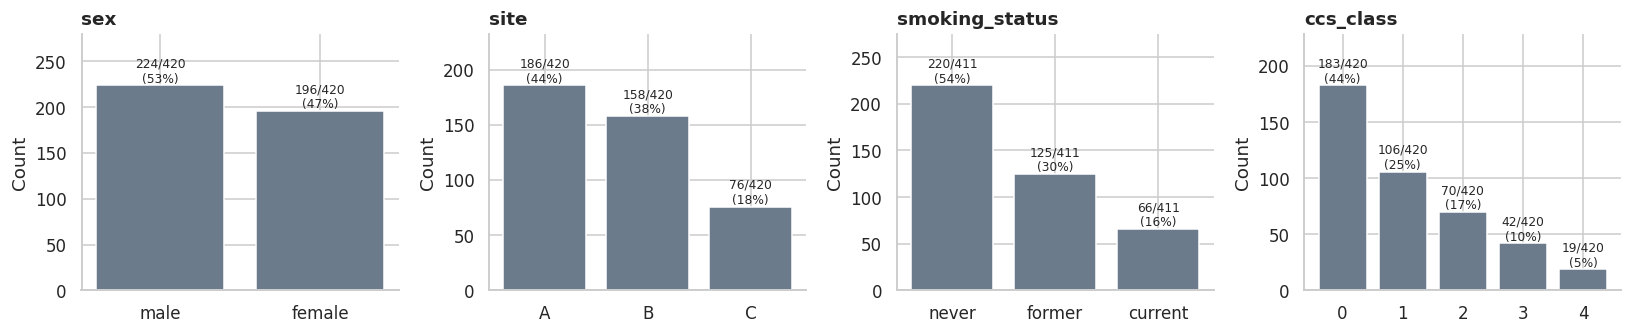

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
plots.bar_counts(base, "sex", axes[0])
plots.bar_counts(base, "site", axes[1], order=["A", "B", "C"])
plots.bar_counts(base, "smoking_status", axes[2], order=["never", "former", "current"])
plots.bar_counts(base, "ccs_class", axes[3], order=[0, 1, 2, 3, 4])
fig.tight_layout()

### 3.2 Continuous variables: every variable on its own scale
A grid of box plots is a fast scan for skew and extreme values. Each variable gets its own axis, because
putting height (cm) and CRP (mg/L) on one axis hides both.

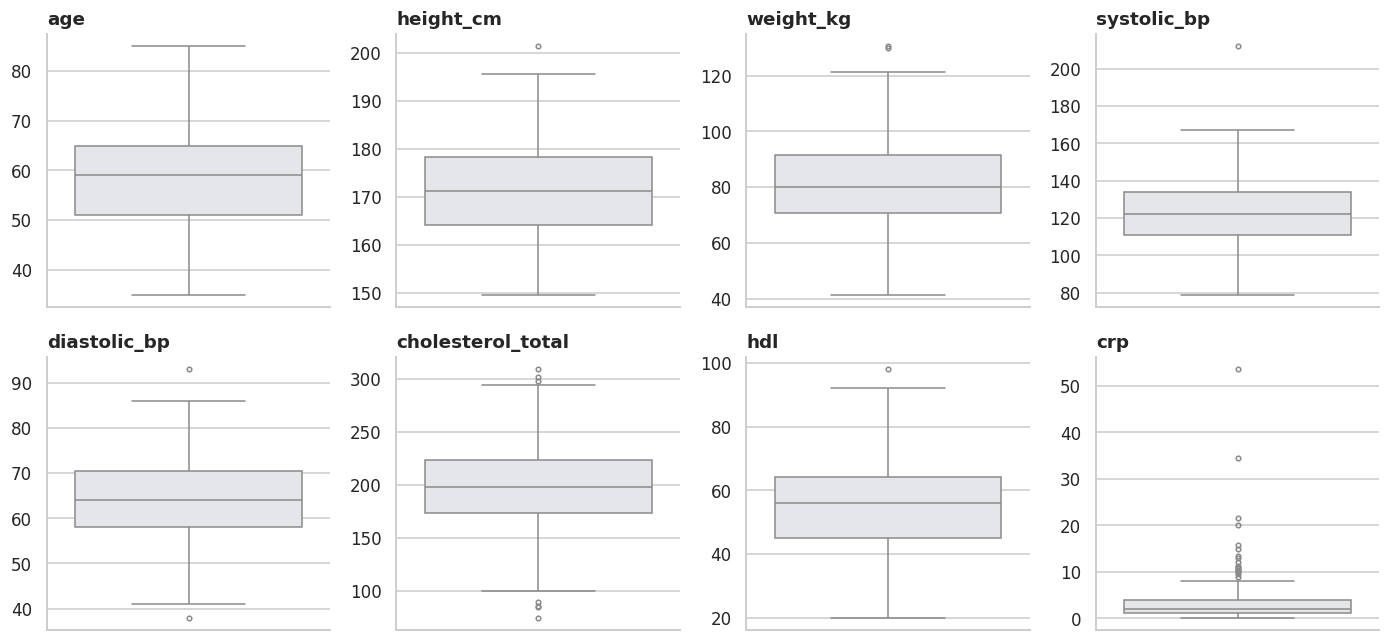

In [17]:
num_cols = ["age", "height_cm", "weight_kg", "systolic_bp", "diastolic_bp",
            "cholesterol_total", "hdl", "crp"]
plots.box_grid(base, num_cols, ncols=4);

In [18]:
shape_table(base, num_cols)

,n,missing,mean,sd,median,q1,q3,skew
age,420.0,0.0,58.27,9.93,59.00,51.00,65.00,-0.03
height_cm,409.0,11.0,171.16,9.22,171.10,164.10,178.30,0.09
weight_kg,390.0,30.0,80.95,15.64,80.05,70.60,91.45,0.26
systolic_bp,419.0,1.0,122.47,16.04,122.00,111.00,134.00,0.42
diastolic_bp,419.0,1.0,64.28,9.05,64.00,58.00,70.50,-0.01
cholesterol_total,379.0,41.0,198.87,39.33,198.00,174.00,223.50,-0.14
hdl,377.0,43.0,55.24,13.35,56.00,45.00,64.00,0.08
crp,290.0,130.0,3.32,4.64,1.97,1.14,3.90,6.16


### 3.3 Histogram and Q-Q plot
The Q-Q plot compares the data with a normal distribution: points on the line mean the shape matches.
Systolic BP is roughly symmetric; CRP is strongly right-skewed.

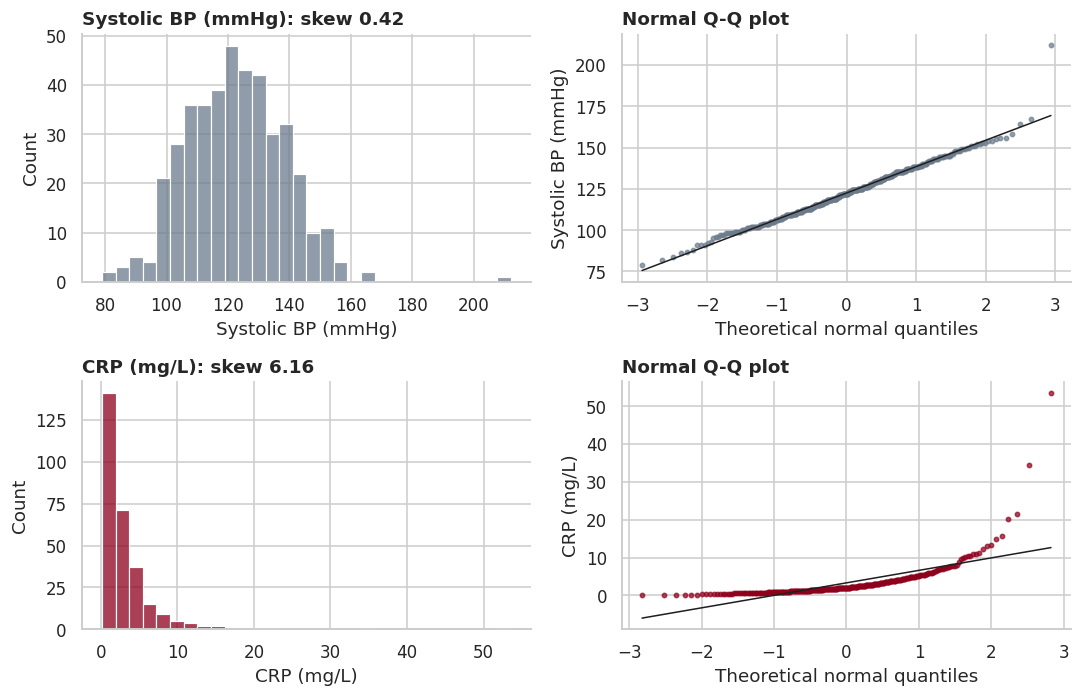

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
plots.hist_qq(base["systolic_bp"], "Systolic BP (mmHg)", axes[0])
plots.hist_qq(base["crp"], "CRP (mg/L)", axes[1], color=plots.RED)
fig.tight_layout()
fig.savefig(FIG / "distributions.png")

### 3.4 By group
Histograms by diabetes status show whether the groups differ in location, spread or shape.
`seaborn.histplot()` replaces the deprecated `distplot()`.

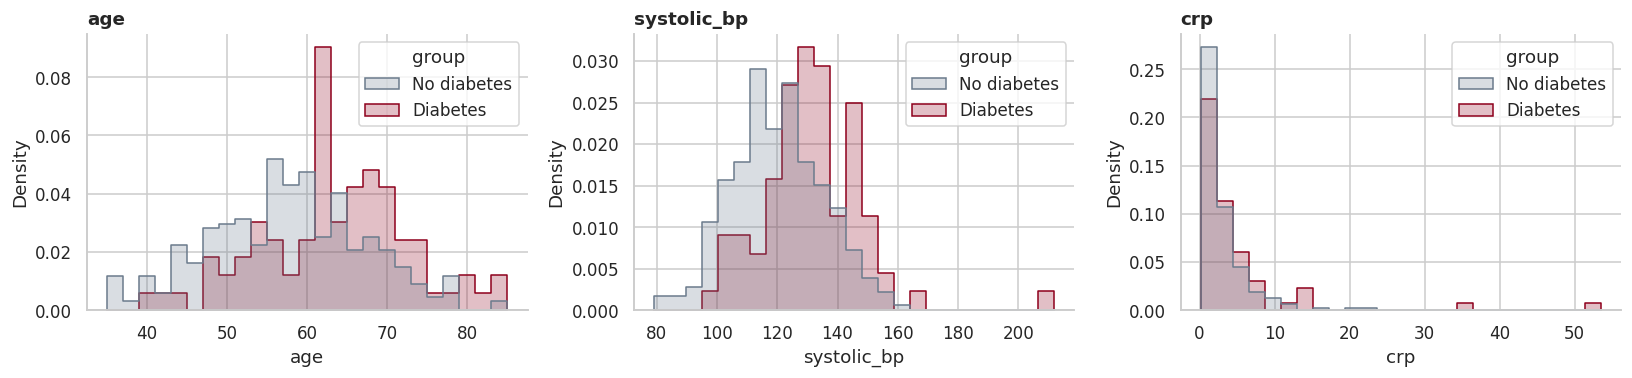

In [20]:
labelled = base.assign(group=base["diabetes"].map(plots.GROUP_LABELS))
palette = {plots.GROUP_LABELS[k]: v for k, v in plots.GROUP_COLORS.items()}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, ["age", "systolic_bp", "crp"]):
    sns.histplot(data=labelled, x=col, hue="group", palette=palette, bins=25,
                 stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(col)
fig.tight_layout()

### 3.5 Normality: evidence, not a gate
A Shapiro-Wilk p-value answers "is there detectable non-normality?", and detectability depends mainly on n.
The cell below runs the test on random subsets of **the same variable**: the shape does not change, only n does.

In [21]:
x = base["systolic_bp"].dropna()          # all non-missing values; no fixed .sample(200)
rng = np.random.default_rng(1)
rows = []
for n in [30, 100, 200, len(x)]:
    p = [stats.shapiro(rng.choice(x, n, replace=False)).pvalue for _ in range(200)]
    rows.append({"n": n, "median Shapiro p": np.median(p), "share with p < 0.05": np.mean(np.array(p) < 0.05)})
pd.DataFrame(rows).round(3)

,n,median Shapiro p,share with p < 0.05
0,30,0.447,0.085
1,100,0.326,0.305
2,200,0.217,0.440
3,419,0.000,1.000


The same, nearly symmetric variable "passes" at small n and "fails" at full n. What to look at instead:
(i) the **sample size per group**, (ii) **skewness and extreme observations**, and (iii) **the quantity the method
assumes is normal**: each group (or the residuals) for a two-sample t-test, the within-patient differences for a
paired t-test, the residuals for linear regression.

In [22]:
shape_table(base, ["systolic_bp", "crp"], by="diabetes")

n  missing    mean     sd  median      q1      q3  skew
variable    diabetes                                                             
systolic_bp 0         336.0      1.0  120.17  15.08  119.00  109.75  131.00  0.11
            1          83.0      0.0  131.78  16.53  132.00  122.50  141.00  1.22
crp         0         228.0    109.0    2.91   3.01    1.94    1.10    3.70  2.92
            1          62.0     21.0    4.82   8.08    2.46    1.45    4.87  4.59

Systolic BP: 337 and 83 patients, skew near 0 apart from one 212 mmHg reading in the diabetes group, so means
and a t-based interval are reliable. CRP: heavily right-skewed in both groups, so it is summarised as
median (IQR) and compared on the log scale (step 7A).

diabetes
no diabetes    57.1
diabetes       63.1


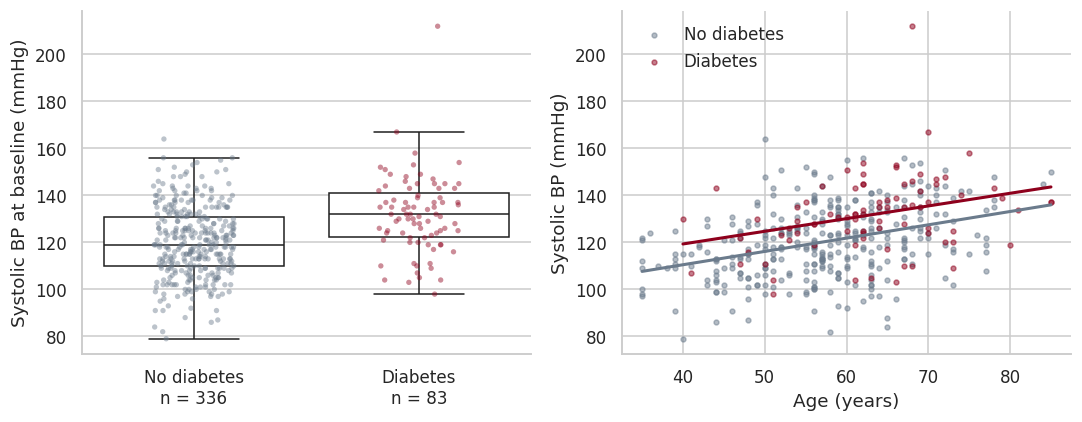

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plots.group_box_strip(base, "systolic_bp", ax=axes[0], ylabel="Systolic BP at baseline (mmHg)")
for g in [0, 1]:
    d = base[base["diabetes"] == g]
    axes[1].scatter(d["age"], d["systolic_bp"], s=10, alpha=0.5, color=plots.GROUP_COLORS[g],
                    label=plots.GROUP_LABELS[g])
    b = np.polyfit(d.dropna(subset=["systolic_bp"])["age"], d["systolic_bp"].dropna(), 1)
    xs = np.linspace(d["age"].min(), d["age"].max(), 10)
    axes[1].plot(xs, np.polyval(b, xs), color=plots.GROUP_COLORS[g], lw=2)
axes[1].set(xlabel="Age (years)", ylabel="Systolic BP (mmHg)"); axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "sbp_by_diabetes_and_age.png")
print(base.groupby("diabetes")["age"].mean().round(1).rename({0: "no diabetes", 1: "diabetes"}).to_string())

SBP rises with age, and patients with diabetes are on average 6 years older. Part of the group difference may
therefore be an age difference: a first hint of **confounding**, handled in step 7A.

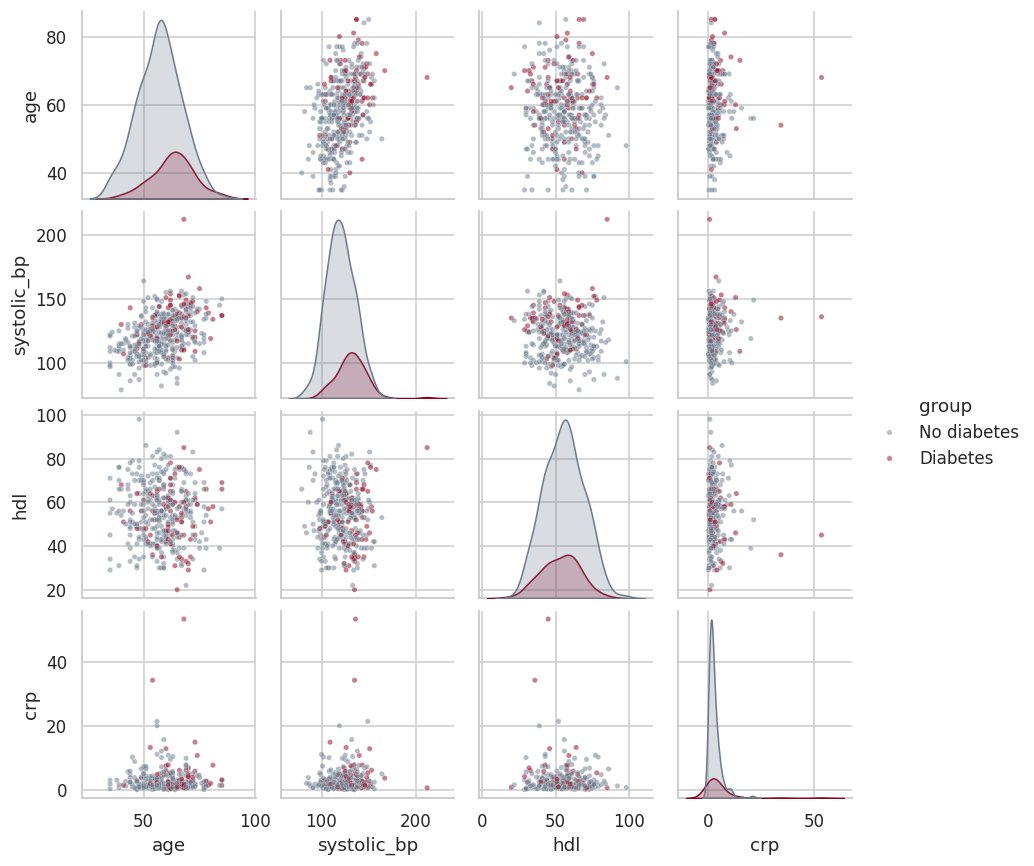

In [24]:
sns.pairplot(labelled[["age", "systolic_bp", "hdl", "crp", "group"]], hue="group",
             palette=palette, plot_kws={"s": 12, "alpha": 0.5}, height=2.0);

---
## 4 · Outliers: flag statistically, judge clinically

The **IQR rule** flags values beyond Q1 − 1.5 × IQR or Q3 + 1.5 × IQR (the box-plot whiskers). It is robust
because quartiles are not pulled by extreme values. A flag is a prompt to look, not proof of an error: in clinical
data an extreme value may be the finding (a hypertensive crisis, a very high CRP during infection).

In [25]:
def iqr_flags(data: pd.DataFrame, cols, k: float = 1.5) -> pd.DataFrame:
    """True where a value lies outside the IQR fences. Flags only; nothing is dropped."""
    out = {}
    for col in cols:
        q1, q3 = data[col].quantile([0.25, 0.75])
        lo, hi = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
        out[col] = data[col].notna() & ~data[col].between(lo, hi)
    return pd.DataFrame(out)

iqr = iqr_flags(base, num_cols)
iqr.sum().rename("IQR flags").to_frame().T

,age,height_cm,weight_kg,systolic_bp,diastolic_bp,cholesterol_total,hdl,crp
IQR flags,0,1,2,1,2,7,1,18


CRP gets many IQR flags because its distribution is skewed: the rule assumes a roughly symmetric shape. On the log
scale fewer values are flagged. For systolic BP, the flagged values are reviewed individually:

In [26]:
print("CRP flags on the log scale:", iqr_flags(base.assign(log_crp=np.log(base["crp"])), ["log_crp"]).sum().iloc[0])
base.loc[iqr["systolic_bp"], ["patient_id", "age", "diabetes", "systolic_bp", "diastolic_bp"]]

CRP flags on the log scale: 8


,patient_id,age,diabetes,systolic_bp,diastolic_bp
303,P0236,68,1,212.0,93.0


212/93 mmHg in a 68-year-old is extreme but physiologically possible, so it is kept and verified. Its influence is
checked with a sensitivity analysis: the main estimate with and without it.

In [27]:
with_all = mean_difference(base, "systolic_bp", "diabetes")
without = mean_difference(base[base["systolic_bp"] != 212], "systolic_bp", "diabetes")
pd.DataFrame([with_all, without], index=["all patients", "without 212 mmHg"])[["estimate", "ci_low", "ci_high", "n1"]].round(1)

,estimate,ci_low,ci_high,n1
all patients,11.6,7.7,15.6,83
without 212 mmHg,10.6,7.2,14.1,82


In [28]:
log.add("4 Outliers", "SBP 212 mmHg (IQR flag)", 1, "kept: plausible; sensitivity analysis shows little change")

---
## 5 · Missing data: explore before any comparison

The aim is to **explore missingness patterns and plausible reasons for missingness**. Patterns are consistent
with a mechanism but cannot prove it; how the data were collected decides which assumption is reasonable.

| Mechanism | Meaning | Clinical example |
|---|---|---|
| MCAR | unrelated to any data | sample lost in transit |
| MAR | explained by observed data | CRP ordered less often in younger patients |
| MNAR | depends on the unobserved value itself | very unwell patients miss the follow-up visit |

In [29]:
missing_summary(df).query("n_missing > 0")

,n_missing,pct_missing
crp,165,30.2
hdl,48,8.8
cholesterol_total,44,8.1
weight_kg,40,7.3
smoking_status,13,2.4
height_cm,13,2.4
diastolic_bp,2,0.4
systolic_bp,2,0.4
visit_date,1,0.2


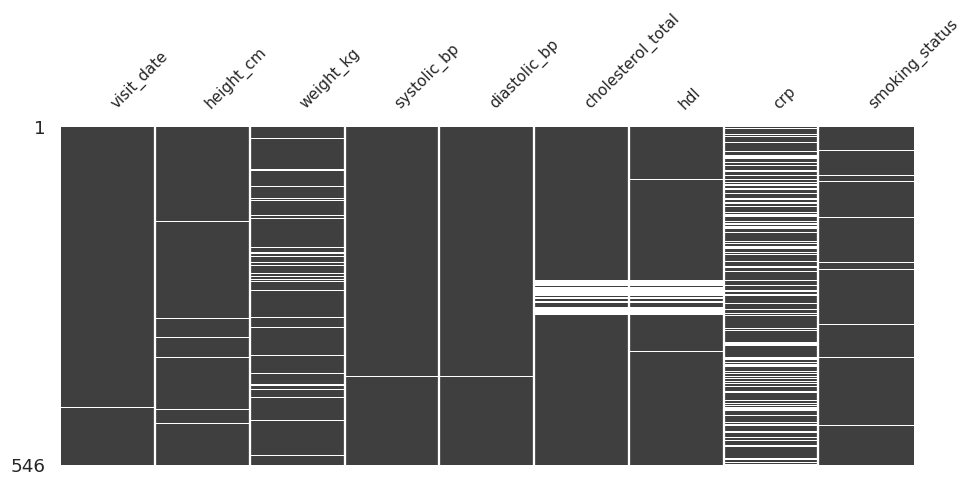

In [30]:
import missingno as msno
cols_with_missing = df.columns[df.isna().any()]
msno.matrix(df.sort_values(["site", "visit_date"])[cols_with_missing], figsize=(10, 4), fontsize=10, sparkline=False);

The matrix is sorted by site and date: the block of missing `hdl` and `cholesterol_total` is visible as one band.
The nullity heatmap shows which variables tend to be missing **together**: values near 1 mean "missing in the same rows".

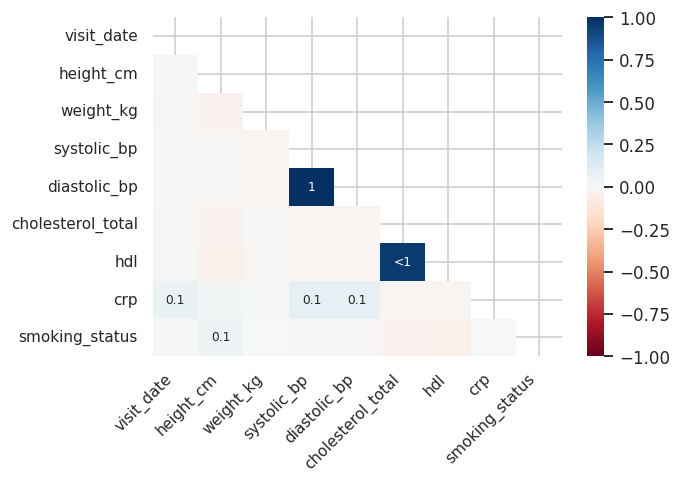

In [31]:
msno.heatmap(df[cols_with_missing], figsize=(6, 4), fontsize=10);

In [32]:
display(missing_by(df, "hdl", "site"))
display(missing_by(df, "crp", "age", bins=[0, 50, 60, 70, 120]))

,n,pct_missing
site,,
A,247,1.2
B,207,21.7
C,92,0.0


,n,pct_missing
age,,
"(0, 50]",121,46.3
"(50, 60]",198,34.3
"(60, 70]",172,21.5
"(70, 120]",55,7.3


### Do rows with missing values differ?
Comparing observed characteristics of rows with and without a missing value shows whether complete cases are a
biased subset. The **standardized mean difference (SMD)** is used instead of a p-value: with many rows tiny
differences become "significant", with few rows important ones do not. |SMD| above about 0.1 is a common flag.

A difference (as for CRP and age) shows the data are **not MCAR**. No difference does **not** prove MCAR, and
no observed-data test can separate MAR from MNAR.

In [33]:
compare_by_missingness(df, "crp", ["age", "diabetes", "systolic_bp", "statin"])

,variable,mean_if_missing,mean_if_observed,smd,n_missing,n_observed
0,age,54.200,59.997,-0.621,165,381
1,diabetes,0.145,0.207,-0.163,165,381
2,systolic_bp,119.380,122.958,-0.218,163,381
3,statin,0.273,0.336,-0.137,165,381


### A simulation: why the mechanism and the method matter
The true answer is known only in simulated data. Starting from patients with complete SBP and age, 30% of SBP
values are removed under each mechanism, then three common approaches are compared with the truth:
complete-case analysis, **mean imputation**, and multiple imputation.

In [34]:
from statsmodels.imputation.mice import MICEData
import warnings

complete = base.dropna(subset=["systolic_bp", "age"])[["systolic_bp", "age", "diabetes"]].reset_index(drop=True)
truth = {"mean": complete["systolic_bp"].mean(), "sd": complete["systolic_bp"].std(),
         "corr_age": complete[["systolic_bp", "age"]].corr().iloc[0, 1]}

def summarise(s, a):
    return {"mean": s.mean(), "sd": s.std(), "corr_age": np.corrcoef(s, a)[0, 1]}

rows = []
for mech in ["MCAR", "MAR", "MNAR"]:
    sim = simulate_missing(complete, "systolic_bp", mech, rate=0.3, driver="age", seed=4)
    obs = sim.dropna()
    rows.append({"mechanism": mech, "method": "complete case", **summarise(obs["systolic_bp"], obs["age"])})
    filled = sim["systolic_bp"].fillna(sim["systolic_bp"].mean())
    rows.append({"mechanism": mech, "method": "mean imputation", **summarise(filled, sim["age"])})
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        imp = MICEData(sim.copy(), k_pmm=5)
        est = []
        for _ in range(20):
            imp.update_all(5)
            d = imp.data
            est.append(summarise(d["systolic_bp"], d["age"]))
    rows.append({"mechanism": mech, "method": "multiple imputation (20)", **pd.DataFrame(est).mean().to_dict()})

sim_table = pd.DataFrame(rows).set_index(["mechanism", "method"]).round(2)
print("Truth:", {k: round(v, 2) for k, v in truth.items()})
sim_table

Truth: {'mean': np.float64(122.47), 'sd': np.float64(16.04), 'corr_age': np.float64(0.4)}


mean     sd  corr_age
mechanism method                                           
MCAR      complete case             122.15  15.65      0.40
          mean imputation           122.15  13.48      0.36
          multiple imputation (20)  122.22  15.58      0.40
MAR       complete case             120.82  15.76      0.41
          mean imputation           120.82  13.55      0.34
          multiple imputation (20)  122.80  16.26      0.44
MNAR      complete case             118.75  15.23      0.37
          mean imputation           118.75  13.05      0.31
          multiple imputation (20)  119.69  15.32      0.38

How to read this table:
* **Mean imputation shrinks the SD and weakens the correlation with age under every mechanism, including MCAR.**
  Filling many gaps with one value removes real variation. It should not be used for inference.
* Under **MCAR**, complete-case analysis is unbiased; it only loses precision.
* Under **MAR** (here missingness depends on age), the complete-case mean is biased; multiple imputation using age
  recovers it, because the imputation model contains the variable that drives missingness.
* Under **MNAR** (high values go missing), no method recovers the truth from the observed data. Only a
  sensitivity analysis under explicit assumptions can show how much conclusions could change.

### Multiple imputation for the real data: impute, analyse, pool
`statsmodels` `MICE` imputes several datasets, fits the same model in each, and pools the results with Rubin's rules.
Identifiers (`patient_id`) are excluded, and the outcome and every analysis variable are included in the imputation
model. In R, the equivalent is `mice()` → `with()` → `pool()`.

`sklearn.impute.IterativeImputer()` by contrast produces **one** completed dataset (iterative *single* imputation):
suitable inside a prediction pipeline (7B), not for pooled inference.

In [35]:
import statsmodels.api as sm
from statsmodels.imputation.mice import MICE

base["bmi"] = base["weight_kg"] / (base["height_cm"] / 100) ** 2
mi_data = base[["systolic_bp", "diabetes", "age", "bmi", "hdl", "crp"]].reset_index(drop=True)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    mi = MICE("systolic_bp ~ diabetes + age + bmi", sm.OLS, MICEData(mi_data)).fit(n_burnin=10, n_imputations=20)
cc = adjusted_effect(base, "systolic_bp ~ diabetes + age + bmi", "diabetes")

k = mi.model.exog_names.index("diabetes")
mi_est, (mi_lo, mi_hi) = np.asarray(mi.params)[k], np.asarray(mi.conf_int())[k]
pd.DataFrame({"estimate": [cc["estimate"], mi_est], "ci_low": [cc["ci_low"], mi_lo],
              "ci_high": [cc["ci_high"], mi_hi], "n used": [cc["n"], len(mi_data)]},
             index=["complete case", "multiple imputation (pooled)"]).round(2)

,estimate,ci_low,ci_high,n used
complete case,6.18,2.45,9.90,378
multiple imputation (pooled),5.32,1.71,8.92,420


In [36]:
log.add("5 Missing", "CRP 30% missing, more often in younger patients (MAR plausible)", base["crp"].isna().sum(),
        "multiple imputation with age in the imputation model; complete-case as sensitivity analysis")
log.add("5 Missing", "HDL missing at site B in 2022 (lipid panel not run)", base["hdl"].isna().sum(),
        "treated as MAR given site and date")

---
## 6 · Features: derive, encode, scale or transform

### 6.1 Derived variables
BMI is computed from measured height and weight, after the height correction in step 2.

In [37]:
df["bmi"] = df["weight_kg"] / (df["height_cm"] / 100) ** 2
base["bmi"].describe().round(1)

count    379.0
mean      27.4
std        4.2
min       17.0
25%       24.6
50%       27.6
75%       30.3
max       39.3
Name: bmi, dtype: float64

### 6.2 Encoding
| Variable type | Encoding | Example |
|---|---|---|
| Nominal | dummy (one-hot) coding; `factor` in R | `sex`, `site`, `smoking_status` |
| Ordinal | ordered integer codes, only when the order is meaningful | `ccs_class` 0 to 4 |
| Binary | 0/1 | `diabetes`, `statin` |
| Target y | `LabelEncoder` is designed for y, not for predictors | `diabetes` as an outcome |

Integer codes for nominal categories (site A = 0, B = 1, C = 2) invent an order and equal spacing that do not exist.

In [38]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

X_reg = pd.get_dummies(base[["sex", "smoking_status"]], drop_first=True)    # regression: one reference level
display(X_reg.head(3))

ordinal = OrdinalEncoder(categories=[[0, 1, 2, 3, 4]])                       # ccs_class: order is meaningful
nominal = OneHotEncoder(handle_unknown="ignore")                             # used inside the pipeline in 7B
print(ordinal.fit_transform(base[["ccs_class"]])[:5].ravel())

,sex_male,smoking_status_former,smoking_status_never
0,False,True,False
1,False,True,False
2,True,False,False


[1. 0. 1. 1. 0.]


### 6.3 Scaling is not transformation
* **Scaling** (z-score, min-max) changes units and keeps the shape. Needed for distance-based methods, PCA,
  clustering and penalised regression. In machine learning, fit the scaler on training data only.
* **Transformation** (log) changes the shape. Justify it by the analysis: multiplicative effects, a model
  assumption, or ratios as the quantity of interest. Differences on the log scale become ratios on the original scale.
* Descriptive summaries stay in interpretable units (mg/L, mmHg).

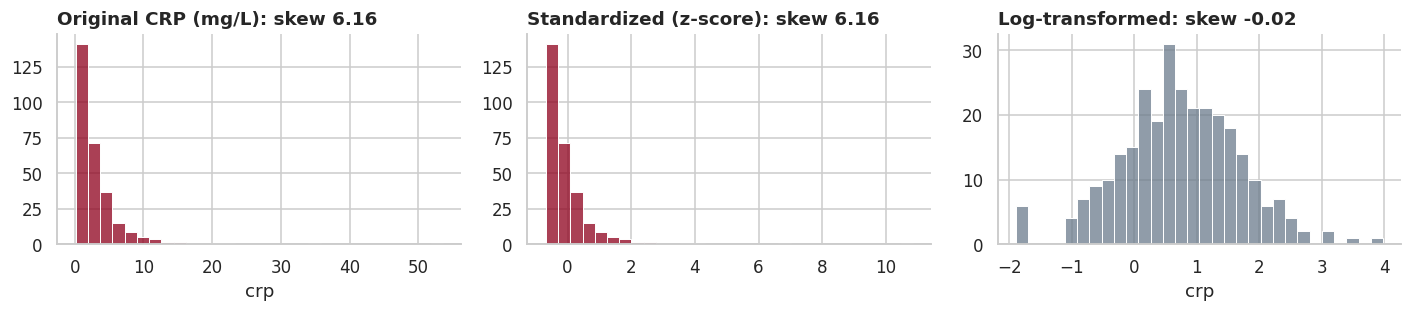

In [39]:
from sklearn.preprocessing import StandardScaler

crp = base["crp"].dropna()
z = StandardScaler().fit_transform(crp.to_frame()).ravel()
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, (v, t, c) in zip(axes, [(crp, "Original CRP (mg/L)", plots.RED), (z, "Standardized (z-score)", plots.RED),
                               (np.log(crp), "Log-transformed", plots.SLATE)]):
    sns.histplot(v, bins=30, color=c, ax=ax)
    ax.set(title=f"{t}: skew {pd.Series(v).skew():.2f}", ylabel="")
fig.tight_layout()

The z-scored CRP is exactly as skewed as the raw values. The spike at the left of the log histogram is the
9 values below the detection limit, all set to 0.15 mg/L: a visible reminder of that decision.

---
## 7A · Statistical inference: effect estimates with uncertainty

### The main comparison
A p-value does not measure the size or clinical importance of a difference. The estimate and its
95% confidence interval do; compare the interval with a difference that matters clinically (here, as an
illustrative threshold, 5 mmHg).

In [40]:
main = mean_difference(base, "systolic_bp", "diabetes")          # Welch t-test
p_txt = "p < 0.001" if main["p_value"] < 0.001 else f"p = {main['p_value']:.3f}"
print(f"Mean systolic BP was {main['estimate']:.1f} mmHg higher in patients with diabetes "
      f"(95% CI {main['ci_low']:.1f} to {main['ci_high']:.1f}; {p_txt}).")

Mean systolic BP was 11.6 mmHg higher in patients with diabetes (95% CI 7.7 to 15.6; p < 0.001).


### Confounding by age
Older patients have more diabetes **and** higher SBP. Adjusting for age in a linear model separates the two.
Treatment, BMI or site could confound in the same way; which variables to adjust for is a subject-matter decision,
made before looking at results.

In [41]:
crude = adjusted_effect(base, "systolic_bp ~ diabetes", "diabetes")
adj_age = adjusted_effect(base, "systolic_bp ~ diabetes + age", "diabetes")
adj_more = adjusted_effect(base, "systolic_bp ~ diabetes + age + bmi + C(sex)", "diabetes")
effects = pd.DataFrame([crude, adj_age, adj_more]).set_index("model").round(2)
effects

,estimate,ci_low,ci_high,p_value,n
model,,,,,
systolic_bp ~ diabetes,11.61,7.91,15.32,0.0,419
systolic_bp ~ diabetes + age,8.24,4.67,11.82,0.0,419
systolic_bp ~ diabetes + age + bmi + C(sex),6.42,2.66,10.17,0.0,378


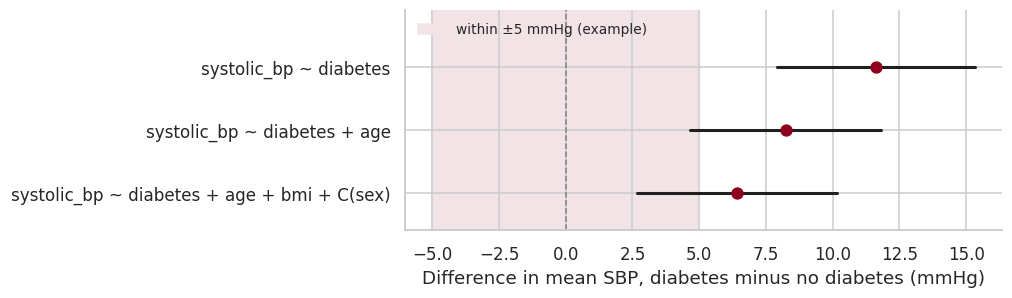

In [42]:
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.axvspan(-5, 5, color="#F1E3E6", zorder=0, label="within ±5 mmHg (example)")
ax.axvline(0, color="grey", ls="--", lw=1)
for i, (name, r) in enumerate(effects.iloc[::-1].iterrows()):
    ax.plot([r.ci_low, r.ci_high], [i, i], color=plots.INK, lw=2)
    ax.scatter(r.estimate, i, color=plots.RED, s=50, zorder=3)
ax.set_yticks(range(len(effects)), effects.index[::-1])
ax.set_xlabel("Difference in mean SBP, diabetes minus no diabetes (mmHg)")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.set_ylim(-0.6, len(effects) - 0.1)
fig.savefig(FIG / "effect_estimates.png")

In [43]:
log.add("7A Inference", "confounding by age", len(base),
        "primary estimate adjusted for age; BMI and sex in a secondary model")

### Many variables at once: effects, intervals and multiplicity
A common pattern is to loop over many variables and let a normality test choose between a t-test and
Mann-Whitney, reporting only p-values. Here instead each variable gets an **effect measure chosen from its
distribution**, a confidence interval, and a p-value adjusted for the number of tests (Benjamini-Hochberg).

With 10 independent tests of true null hypotheses at α = 0.05, the chance of at least one false positive is
1 − 0.95¹⁰ ≈ 40%.

In [44]:
specs = {
    "systolic_bp": "mean", "diastolic_bp": "mean", "bmi": "mean", "hdl": "mean",
    "cholesterol_total": "mean",
    "crp": "log",                           # right-skewed: ratio of geometric means
    "smoking_status": "prop:current",       # categorical: difference in percentage points
    "statin": "prop:1",
}
many = compare_groups(base, "diabetes", specs, adjust="fdr_bh")
many.round({"estimate": 2, "ci_low": 2, "ci_high": 2, "p_value": 4, "p_fdr_bh": 4})

,variable,measure,estimate,ci_low,ci_high,p_value,n1,n0,p_fdr_bh
0,systolic_bp,difference in means,11.61,7.67,15.56,0.0000,83,336,0.0000
1,diastolic_bp,difference in means,4.24,2.02,6.45,0.0002,83,336,0.0004
2,bmi,difference in means,3.05,2.12,3.98,0.0000,78,301,0.0000
3,hdl,difference in means,-2.40,-5.74,0.94,0.1579,74,303,0.1579
4,cholesterol_total,difference in means,-21.32,-31.94,-10.70,0.0001,76,303,0.0003
5,crp,ratio of geometric means,1.37,1.04,1.83,0.0281,62,228,0.0321
6,smoking_status = current,difference in % (points),14.98,4.60,25.36,0.0009,82,329,0.0013
7,statin = 1,difference in % (points),42.53,31.39,53.67,0.0000,83,337,0.0000


`statin` shows a large difference: patients with diabetes are more often treated. That is expected clinically and is
itself a potential confounder for cholesterol. A table like this describes; it does not explain.

For reference, the tests behind the measures: Welch t-test (means; robust here because groups are large and close to
symmetric), Welch t-test on log values (CRP), chi-square or Fisher's exact test (proportions). Mann-Whitney U tests
whether values in one group tend to be larger; it compares medians only if the two distributions have the same shape.

---
## 7B · Predictive modelling: avoid leakage

Prediction asks a different question ("which patients are likely to have diabetes?") with different rules:
1. **Split by patient** (and by time or site when the model will be used in new periods or centres).
2. **Fit every learned step on training folds only**: imputation, encoding, scaling, feature selection.
   A `Pipeline` guarantees this inside cross-validation.
3. **Evaluate on held-out patients**, then on temporal or external data.

This example uses all visits, so it also shows what happens if visits of the same patient end up in both training
and test folds.

In [45]:
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, KFold, cross_val_score
from sklearn.pipeline import make_pipeline

num_cols_ml = ["age", "bmi", "systolic_bp", "hdl", "crp"]
cat_cols_ml = ["sex", "smoking_status"]
prep = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num_cols_ml),
    (make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat_cols_ml),
)
model = make_pipeline(prep, LogisticRegression(max_iter=1000))

X, y, groups = df[num_cols_ml + cat_cols_ml], df["diabetes"], df["patient_id"]
from sklearn.ensemble import RandomForestClassifier
forest = make_pipeline(prep, RandomForestClassifier(n_estimators=300, random_state=0))

rows = []
for name, m in [("logistic regression", model), ("random forest", forest)]:
    grouped = cross_val_score(m, X, y, groups=groups, cv=GroupKFold(n_splits=5), scoring="roc_auc")
    naive = cross_val_score(m, X, y, cv=KFold(n_splits=5, shuffle=True, random_state=0), scoring="roc_auc")
    rows.append({"model": name, "AUC, GroupKFold (patients kept together)": grouped.mean(),
                 "AUC, KFold on visits (leaky)": naive.mean()})
pd.DataFrame(rows).set_index("model").round(3)

,"AUC, GroupKFold (patients kept together)","AUC, KFold on visits (leaky)"
model,,
logistic regression,0.790,0.791
random forest,0.743,0.788


The logistic model barely changes. The random forest, which can memorise a patient from their other visit,
looks better when visits of the same patient are split across folds: that apparent gain is leakage. Only the
grouped estimate answers the real question, performance on **new** patients.

A clinical prediction model would also need calibration, a pre-specified predictor set and external
validation. See the scikit-learn page on [common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html).

---
## 8 · Report

### Table 1: cohort summary
Baseline visit, one row per patient. Continuous variables as mean (SD) or median (IQR) according to their shape
(step 3); categorical variables as n/N (%) with N = non-missing values; missing counts for every variable.
No p-values: the formal comparison is in 7A, with effect estimates.

In [46]:
table1 = build_table1(
    base, group_col="diabetes",
    continuous={"age": "mean", "bmi": "mean", "systolic_bp": "mean", "crp": "median"},
    categorical={"sex": ["female"], "smoking_status": ["never", "former", "current"], "statin": [1]},
    labels={"age": "Age, years", "bmi": "BMI, kg/m²", "systolic_bp": "Systolic BP, mmHg",
            "crp": "CRP, mg/L", "sex": "Sex", "smoking_status": "Smoking", "statin": "On statin"},
    group_labels={0: "No diabetes", 1: "Diabetes"},
)
table1.to_csv("outputs/table1.csv")
table1

Overall       No diabetes          Diabetes Missing
Characteristic               Level                                                                
N                                                  420               337                83        
Age, years, mean (SD)                       58.3 (9.9)        57.1 (9.7)        63.1 (9.3)       0
BMI, kg/m², mean (SD)                       27.4 (4.2)        26.8 (4.1)        29.9 (3.6)      41
Systolic BP, mmHg, mean (SD)              122.5 (16.0)      120.2 (15.1)      131.8 (16.5)       1
CRP, mg/L, median (IQR)               2.0 (1.1 to 3.9)  1.9 (1.1 to 3.7)  2.5 (1.4 to 4.9)     130
Sex, n/N (%)                 female      196/420 (47%)     147/337 (44%)       49/83 (59%)       0
Smoking, n/N (%)             never       220/411 (54%)     191/329 (58%)       29/82 (35%)       9
                             former      125/411 (30%)      95/329 (29%)       30/82 (37%)        
                             current      66/411 (16%)      43/329 (13%)       23/82 (28%)        
On statin, n/N (%)           1           135/420 (32%)      80/337 (24%)       55/83 (66%)       0

### The decision log
Every change to the data and every analysis choice, with the rows affected. This is part (iv) of the EDA
deliverable described in the slides, next to (i) Table 1, (ii) three informative plots in `outputs/figures/`
and (iii) the problems identified.

In [47]:
decisions = log.to_frame()
decisions.to_csv("outputs/decision_log.csv", index=False)
decisions

,step,issue,rows_affected,decision
0,2 Clean,sex had 5 spellings,9,standardised to female / male
1,2 Clean,"CRP recorded as ""<0.3"" (below detection limit)",9,set to 0.15 mg/L (LOD/2); flag kept in crp_bel...
2,2 Clean,exact duplicate records,4,removed (copies of another row)
3,2 Clean,"cholesterol in mmol/L at site C, 2023",46,converted to mg/dL (x 38.67) after confirming ...
4,2 Clean,diastolic >= systolic (likely swapped at entry),2,both values set to missing; source query raised
5,2 Clean,height_cm = 17.2 (likely 172),1,set to missing; source query raised
6,2 Clean,follow-up dated before baseline,1,date set to missing; visit kept
7,2 Clean,unit of analysis,420,"baseline visit (visit 1), one row per patient"
8,4 Outliers,SBP 212 mmHg (IQR flag),1,kept: plausible; sensitivity analysis shows li...
9,5 Missing,"CRP 30% missing, more often in younger patient...",130,multiple imputation with age in the imputation...


---
## EDA checklist

**Before** · study question, population and outcome written down · unit of analysis defined (patient, visit or specimen) · data dictionary with units, codes and missing-value codes

**Clean** · labels, types and missing codes fixed · exact duplicates removed, repeat visits kept · units, dates and impossible values checked; decisions logged

**Explore** · histogram and Q-Q plot for each key variable, per group · outliers judged against clinical plausibility · missingness explored by variable, site and patient group

**Decide and report** · path chosen: inference or prediction · effect estimates with CIs, multiplicity and confounding addressed, or a leakage-safe pipeline · Table 1, plots, problems and decisions shared

All links: see **Resources by task** in `README.md`.